# 2. Collision and configuration space

In this notebook, we build the collision model of the vehicle and lift the map
from the plane to the three-dimensional configuration space the planner
searches. Whether a position is free depends on where the vehicle points: the
forklift is five times longer than it is wide, so the question has no answer
until the heading is fixed. The labels drawn on the figures are in French, as
in the thesis.

**Summary**

1. [Why one circle is not enough](#1)
2. [Covering the footprint with discs](#2)
3. [The collision test](#3)
4. [Lifting the map to $(x, y, \theta)$](#4)

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt

from shfm import DEFAULT_VEHICLE
from shfm.figures import save

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

<a id='1'></a>
## 1. Why one circle is not enough

The simplest collision model is a single disc enclosing the vehicle. It is
exact for a round robot and unsuited to a long one: the disc that contains a
3.65 m forklift has a radius of nearly 1.9 m, so the model rejects any corridor
narrower than 3.7 m, although the vehicle is 70 cm wide.

In [2]:
v = DEFAULT_VEHICLE
enclosing = 0.5 * np.hypot(v.length, v.width)
print("enclosing disc radius   %.2f m" % enclosing)
print("corridor it demands     %.2f m" % (2 * enclosing))
print("width actually needed   %.2f m" % v.width)

enclosing disc radius   1.86 m
corridor it demands     3.72 m
width actually needed   0.70 m


<a id='2'></a>
## 2. Covering the footprint with discs

We use a compromise: a chain of overlapping discs along the vehicle axis. The
collision test then reduces to a lookup in the distance transform of the map,
shifted along the axis, which is fast enough to evaluate on every grid cell and
every orientation.

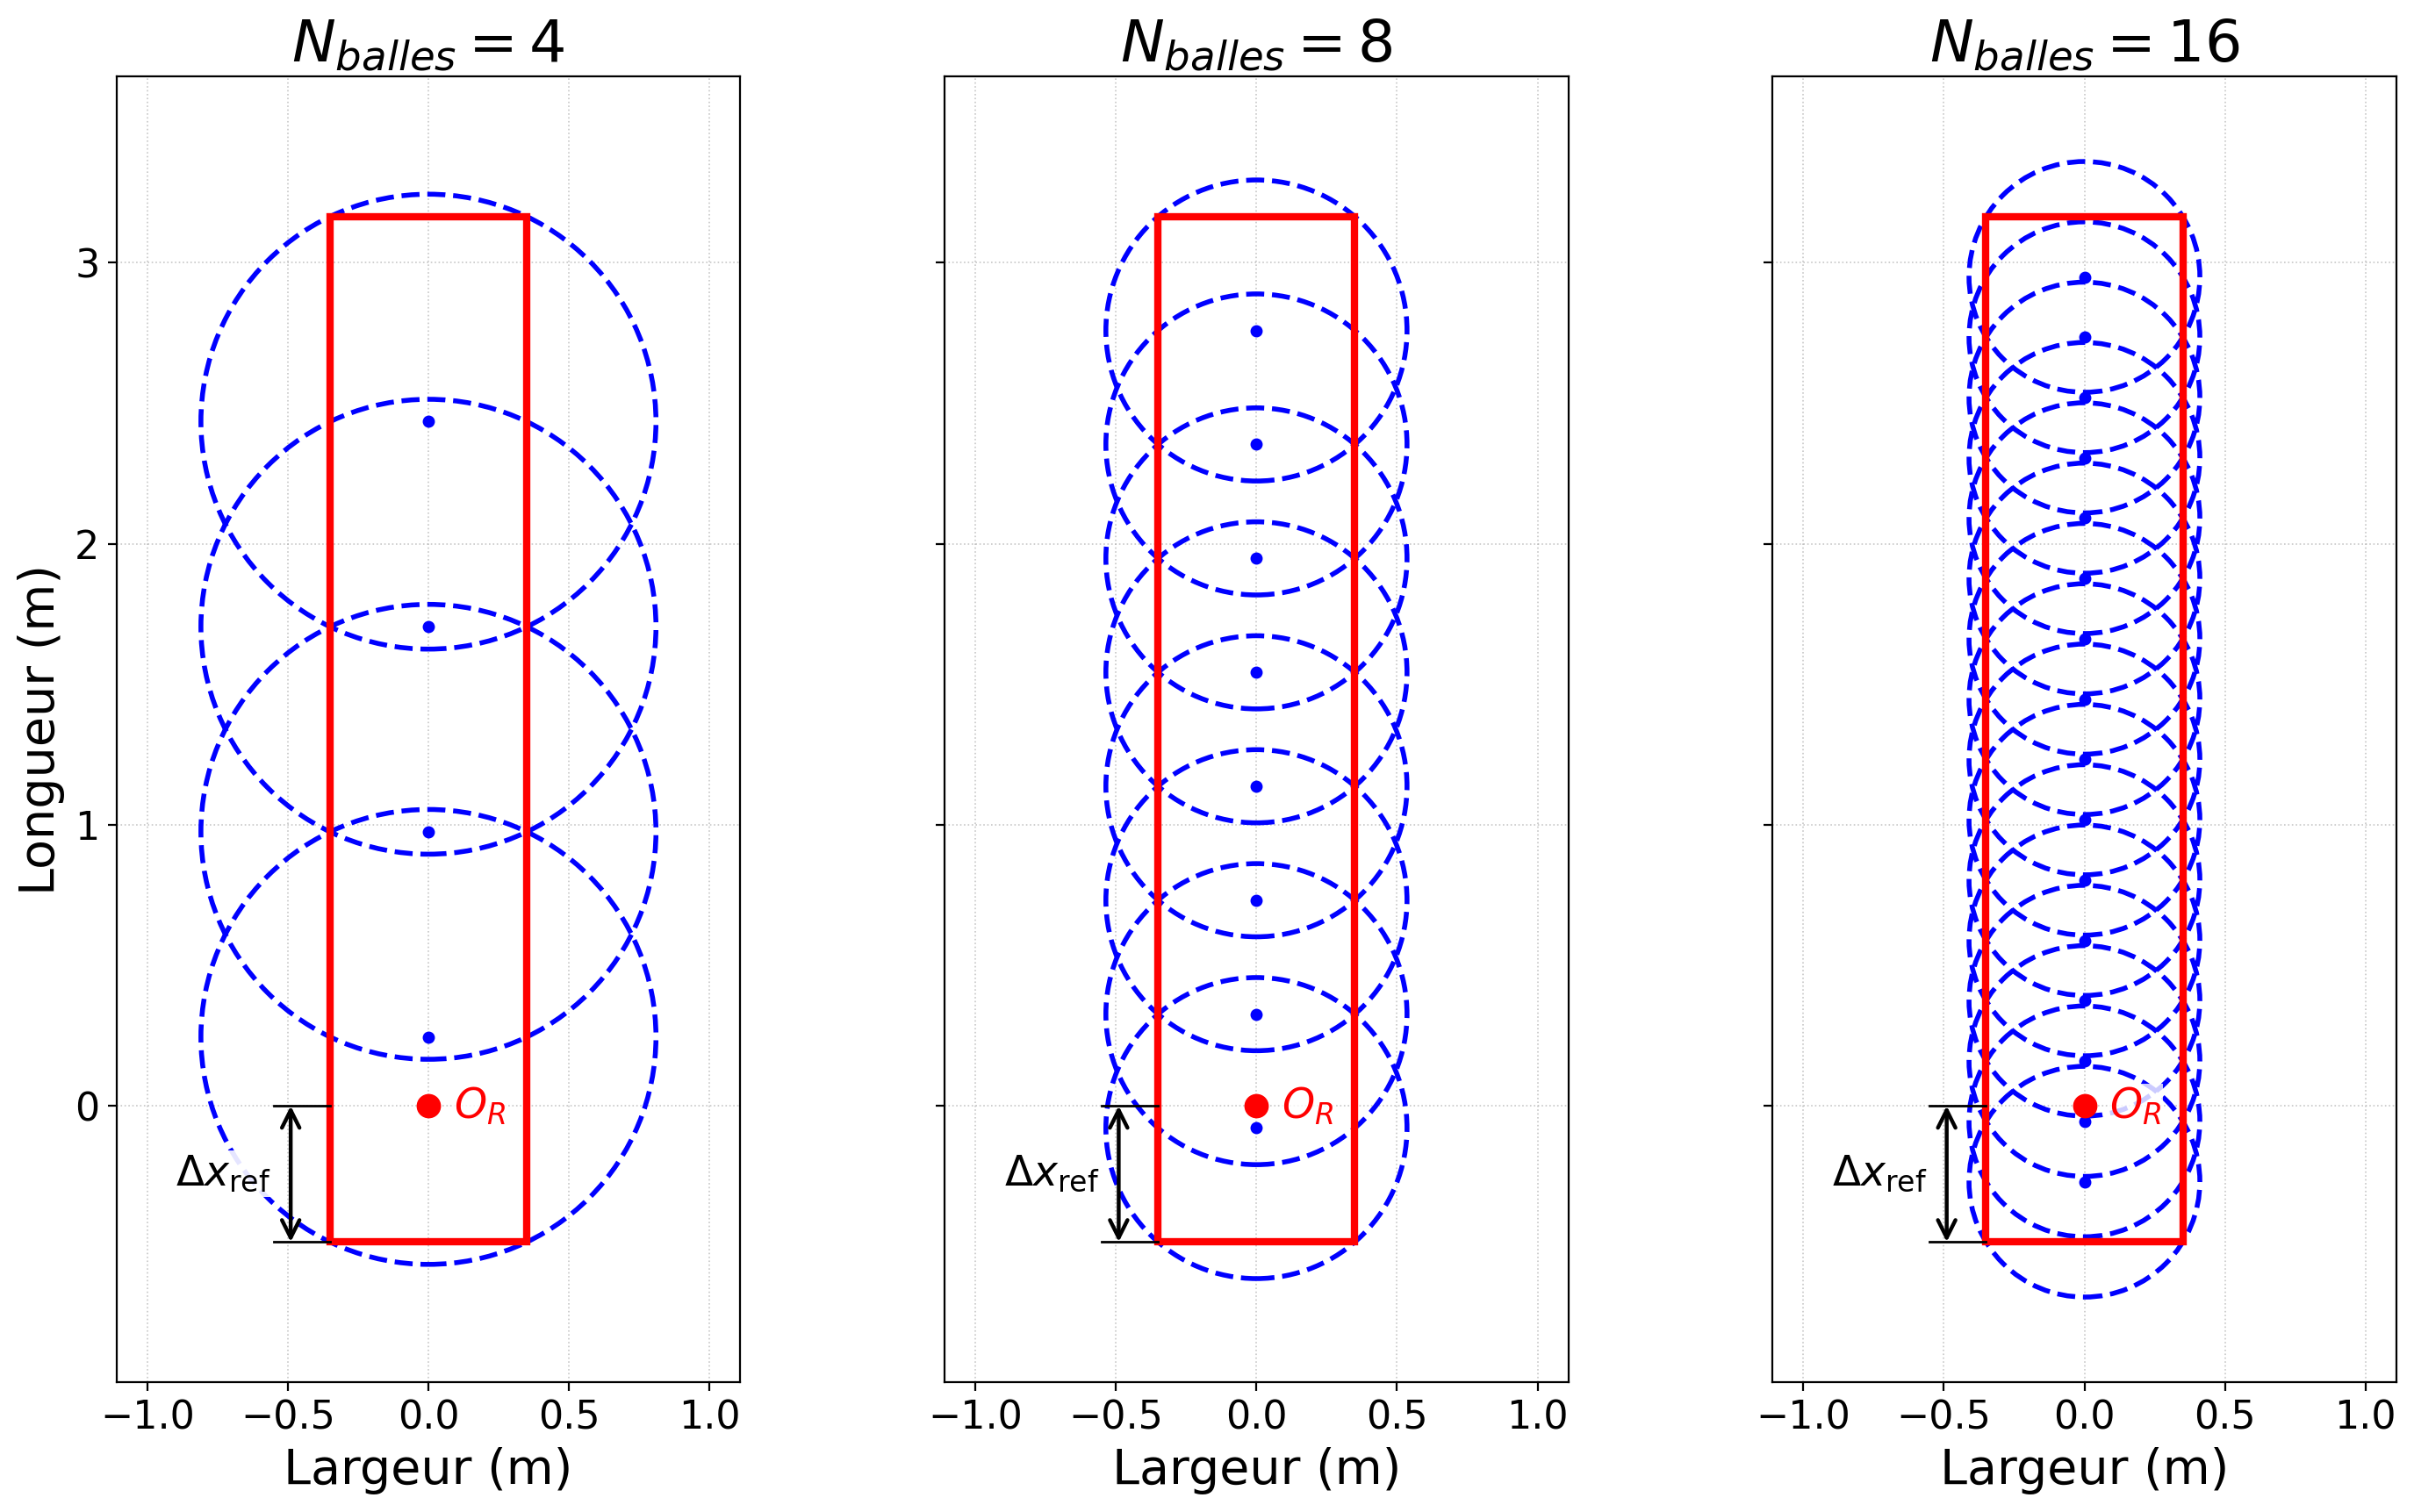

In [3]:
from shfm import generators as GEN
from IPython.display import Image, display

# The disc covering, at three disc counts: 4, 8 and 16.
# The script lives in generators/.
GEN.run("multiball")
display(Image(GEN.figure_path("multiball_combined.png")))

More discs give a tighter fit, at a higher cost. The planner uses twelve.

The radius depends on the disc positions. The outermost centres are one
full spacing from each end of the vehicle, so the end discs reach the corners
only with a radius of `hypot(width/2, step)`, which is the one used. The
covering is therefore tight at the four corners and generous between discs, and
it reaches past the sides and the ends: it overestimates the vehicle slightly,
which is safe but costs a little clearance in the narrowest passages.

In [4]:
step = v.length / (v.n_balls + 1)
r = v.ball_radius(1.0)
print("spacing between centres   %.3f m" % step)
print("radius used               %.3f m" % r)
print("reach past each side      %.3f m" % (r - 0.5 * v.width))
print("reach past each end       %.3f m" % (r - step))

spacing between centres   0.281 m
radius used               0.449 m
reach past each side      0.099 m
reach past each end       0.168 m


<a id='3'></a>
## 3. The collision test

A configuration collides when any disc overlaps an obstacle. Below, we test
the same position against a wall at two headings. The script draws a generic
rectangle rather than the forklift, and shows that the configuration obstacle,
the wall dilated by the footprint, changes shape with the heading.

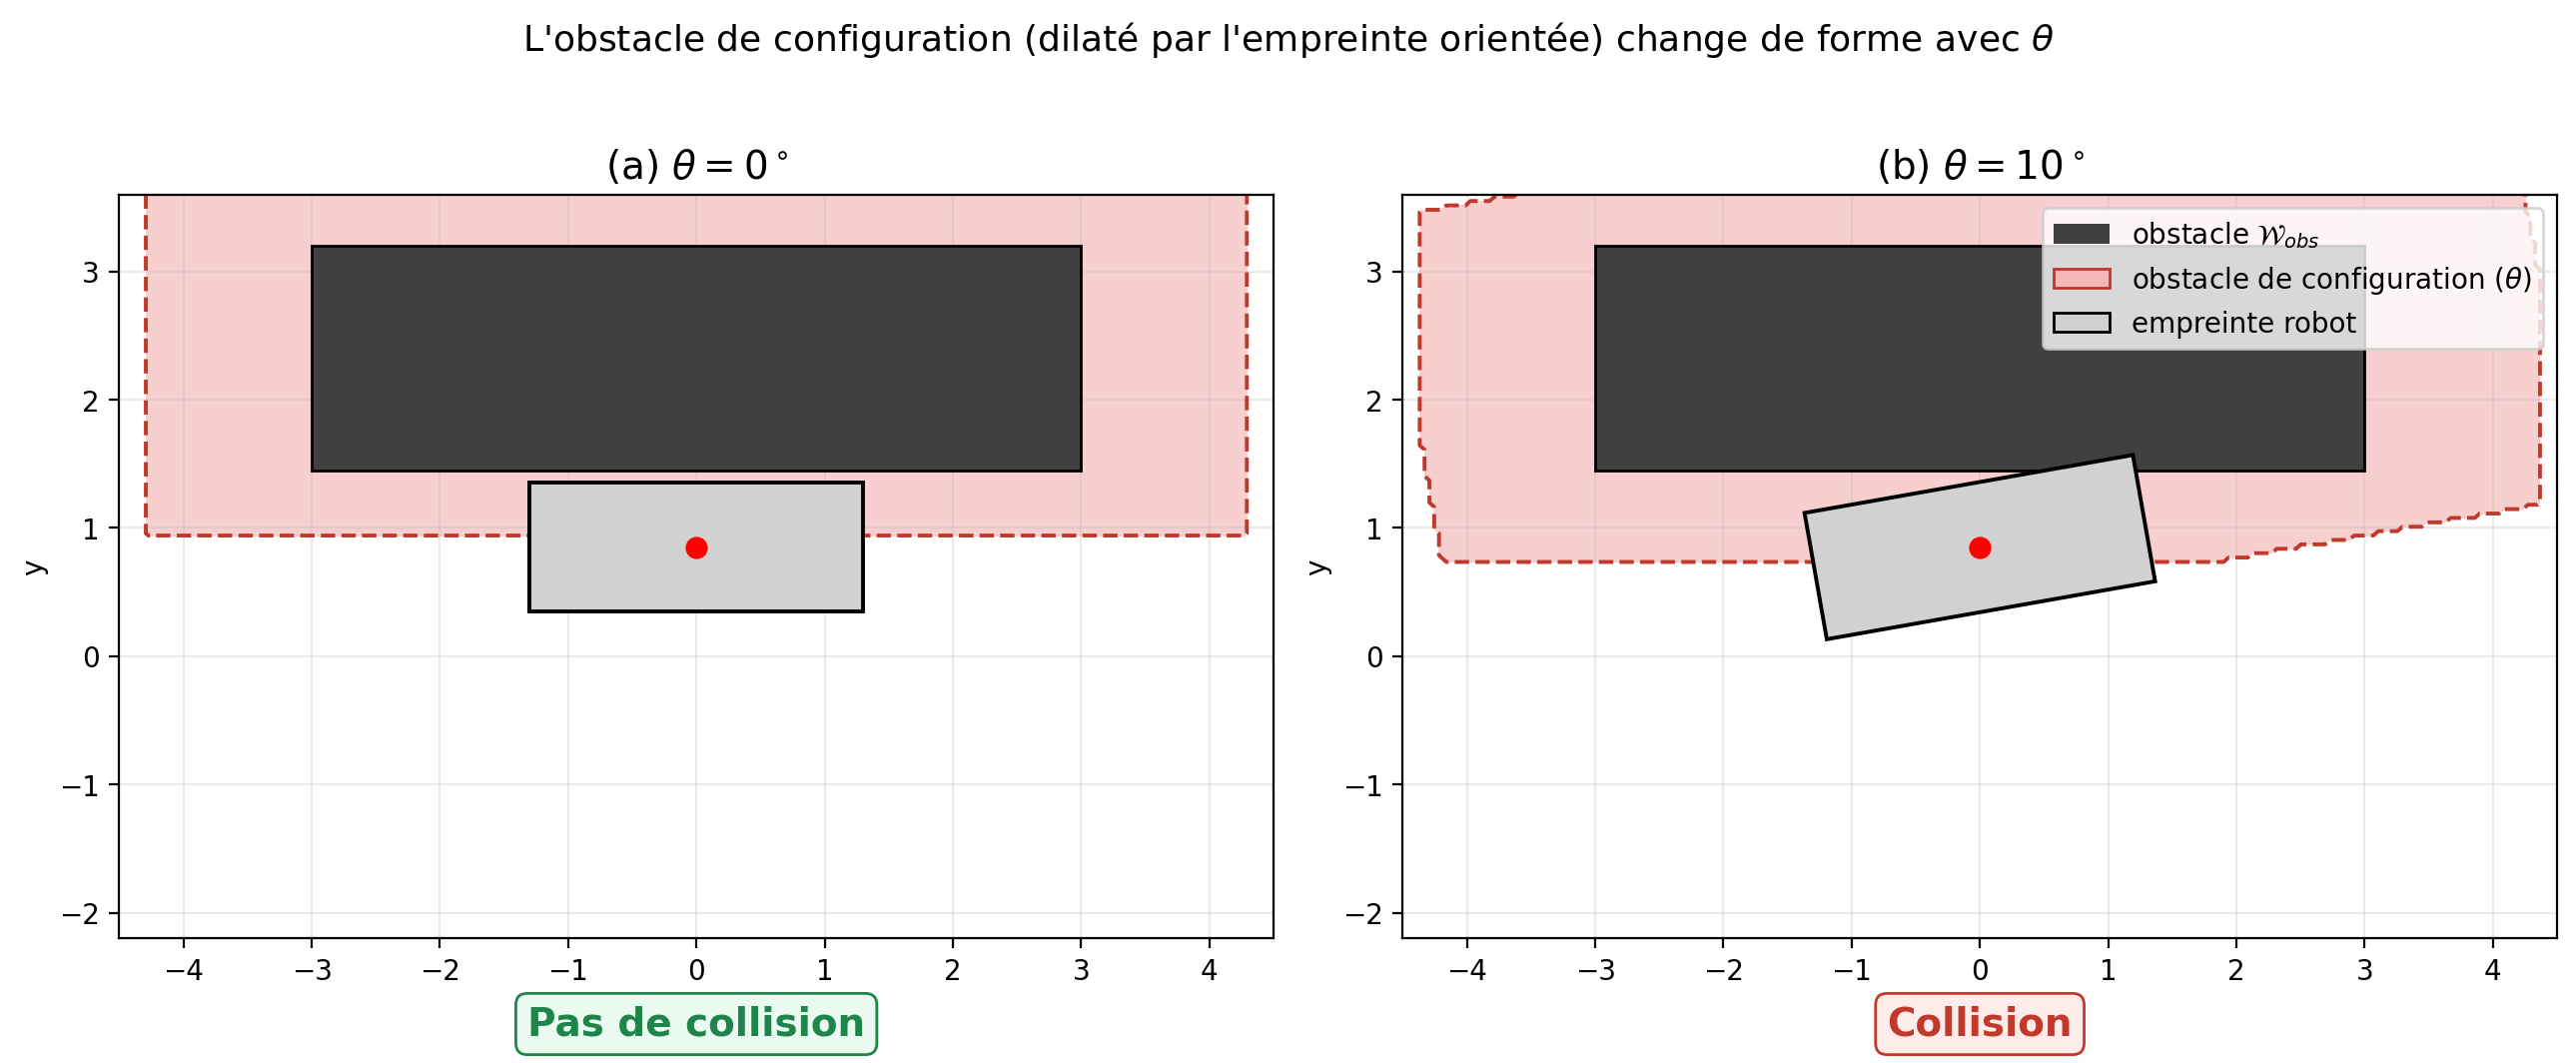

In [5]:
from shfm import generators as GEN
from IPython.display import Image, display

# The collision test, at two headings.
# The script lives in generators/.
GEN.run("collision")
display(Image(GEN.figure_path("collision_check.png")))

<a id='4'></a>
## 4. Lifting the map to $(x, y, \theta)$

Repeating that test for every cell and every sampled orientation gives a
three-dimensional occupancy map. The planner searches this map, in which the
length of the vehicle becomes a hard constraint. Below, we lift a corridor.

In [6]:
import numpy as np
from shfm import from_occupancy

# A corridor twelve cells wide, 3 m at zoom 4, running along x.
gap = np.zeros((110, 60), bool)
gap[:, :24] = True
gap[:, 36:] = True

env = from_occupancy(gap, zoom=4, n_theta=32, name="corridor")
free = ~env.walls3
print(env)
print("free fraction of the plane          %.3f" % (~gap).mean())
print("free fraction of the lifted space   %.3f" % free.mean())

Environment(name='corridor', shape=(110, 60), n_theta=32, zoom=4, 1 unit = 0.25 m)
free fraction of the plane          0.200
free fraction of the lifted space   0.035


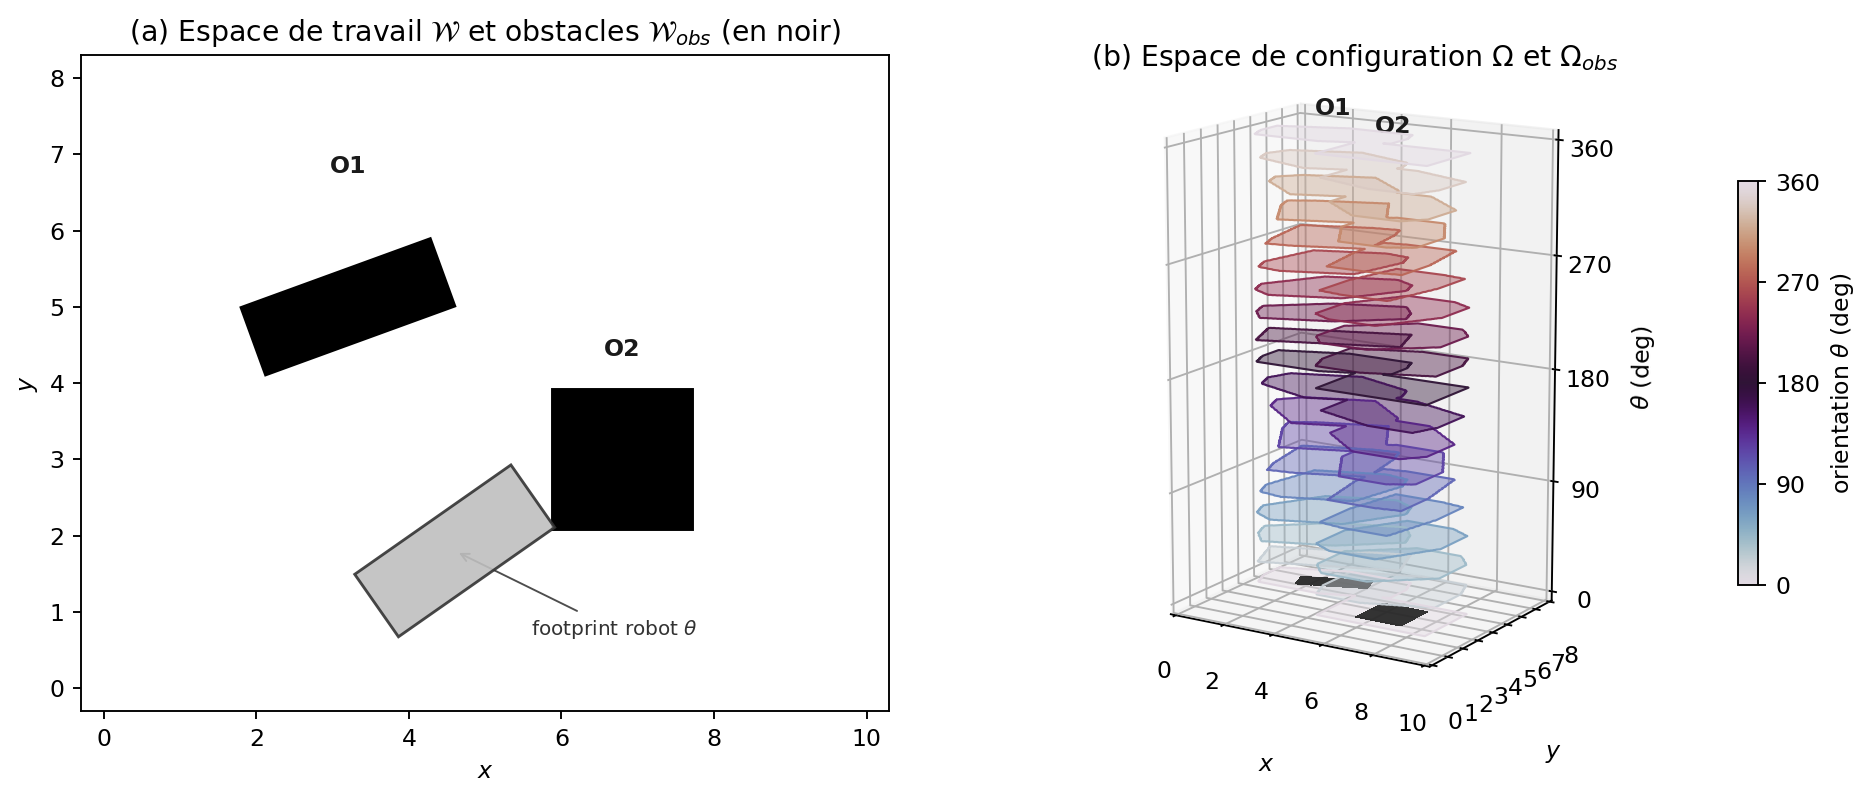

In [7]:
from shfm import generators as GEN
from IPython.display import Image, display

# The workspace and its lift to the configuration space.
# The script lives in generators/.
GEN.run("env_2d3d")
display(Image(GEN.figure_path("env_2d3d_combined.png")))

The script draws a generic workspace and footprint rather than the corridor
and the forklift. The corridor built above is 3 m wide and the vehicle 3.65 m
long, so a cell of
the corridor is free only for headings close to its axis: 3.5 % of the lifted
configurations are free, against 20 % of the plane. A planar map cannot
express this dependence.

---

Previous: [1. The vehicle and its kinematics](01_vehicle_and_kinematics.ipynb)
Next: [3. Hamiltonian Fast Marching](03_hamiltonian_fast_marching.ipynb)